1. Connecting to your Google Drive...
Mounted at /content/drive

File already exists in your Google Drive! Loading directly from path: /content/drive/MyDrive/DermaMNIST_Data/dermamnist_64.npz

DATASET LOADED FROM DRIVE
Permanent Path: /content/drive/MyDrive/DermaMNIST_Data/dermamnist_64.npz
Training images shape:   (7007, 64, 64, 3) | Labels: (7007, 1)
Validation images shape: (1003, 64, 64, 3) | Labels: (1003, 1)
Test images shape:       (2005, 64, 64, 3) | Labels: (2005, 1)


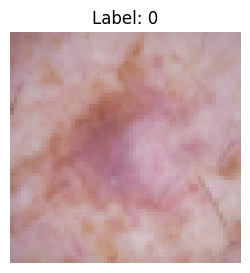

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive, files

# 1. Mount Google Drive (It will ask for permission to connect)
print("1. Connecting to your Google Drive...")
drive.mount('/content/drive')

# Define the folder path in your Drive where you want to save the dataset
drive_folder = '/content/drive/MyDrive/DermaMNIST_Data/'
drive_file_path = os.path.join(drive_folder, 'dermamnist_64.npz')

# 2. Check if the file already exists in Drive to avoid uploading again
if not os.path.exists(drive_file_path):
    print("\nFile not found in Google Drive. Please upload 'dermamnist_64.npz' now:")
    os.makedirs(drive_folder, exist_ok=True)

    # Upload from local computer
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]

    # Move the uploaded file directly to your Google Drive folder
    import shutil
    shutil.move(file_name, drive_file_path)
    print(f"\nSuccessfully uploaded and saved to permanent path: {drive_file_path}")
else:
    print(f"\nFile already exists in your Google Drive! Loading directly from path: {drive_file_path}")

# 3. Load the dataset using the Google Drive path
data = np.load(drive_file_path)

# 4. Extract your train, validation, and test splits
x_train = data['train_images']
y_train = data['train_labels']
x_val = data['val_images']
y_val = data['val_labels']
x_test = data['test_images']
y_test = data['test_labels']

# 5. Print confirmation and shapes
print("\n" + "="*40)
print("DATASET LOADED FROM DRIVE")
print("="*40)
print(f"Permanent Path: {drive_file_path}")
print(f"Training images shape:   {x_train.shape} | Labels: {y_train.shape}")
print(f"Validation images shape: {x_val.shape} | Labels: {y_val.shape}")
print(f"Test images shape:       {x_test.shape} | Labels: {y_test.shape}")
print("="*40)

# 6. Quick visualization to verify
plt.figure(figsize=(3, 3))
plt.imshow(x_train[0])
plt.title(f"Label: {y_train[0][0]}")
plt.axis('off')
plt.show()

In [ ]:
# ================================================================
# CELL 1 — IMPORTS & CONFIGURATION
# ================================================================

import os, gc, warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             balanced_accuracy_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.callbacks import (EarlyStopping, ModelCheckpoint,
                                        ReduceLROnPlateau)

warnings.filterwarnings('ignore')
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# ── Hyperparameters ──────────────────────────────────────────────
IMG_SIZE     = 128       # upsample 64 → 128 (richer EfficientNet features)
BATCH_SIZE   = 32
NUM_CLASSES  = 7
AUTOTUNE     = tf.data.AUTOTUNE
DROPOUT      = 0.40
LABEL_SMOOTH = 0.10

EPOCHS_HEAD  = 20        # Phase 1 : head only
LR_HEAD      = 1e-3

EPOCHS_FT    = 60        # Phase 2 : fine-tune
LR_FT        = 1e-4
LR_FT_MIN    = 1e-6
UNFREEZE_TOP = 100       # unfreeze top N backbone layers in Phase 2

CLASS_NAMES  = [
    'Actinic Ker.', 'Basal Cell Ca.', 'Benign Ker.',
    'Dermatofibroma', 'Melanoma', 'Nevi', 'Vascular'
]

SAVE_PATH = '/content/drive/MyDrive/DermaMNIST_Data/best_model.keras'

print(f"TF {tf.__version__}  |  GPU: {bool(tf.config.list_physical_devices('GPU'))}")
print(f"IMG={IMG_SIZE}   BATCH={BATCH_SIZE}   CLASSES={NUM_CLASSES}")

TF 2.20.0  |  GPU: False
IMG=128   BATCH=32   CLASSES=7


Train  (7007, 64, 64, 3)  Labels (7007, 1)
Val    (1003, 64, 64, 3)    Labels (1003, 1)
Test   (2005, 64, 64, 3)   Labels (2005, 1)
Range  [0, 255]   dtype=uint8


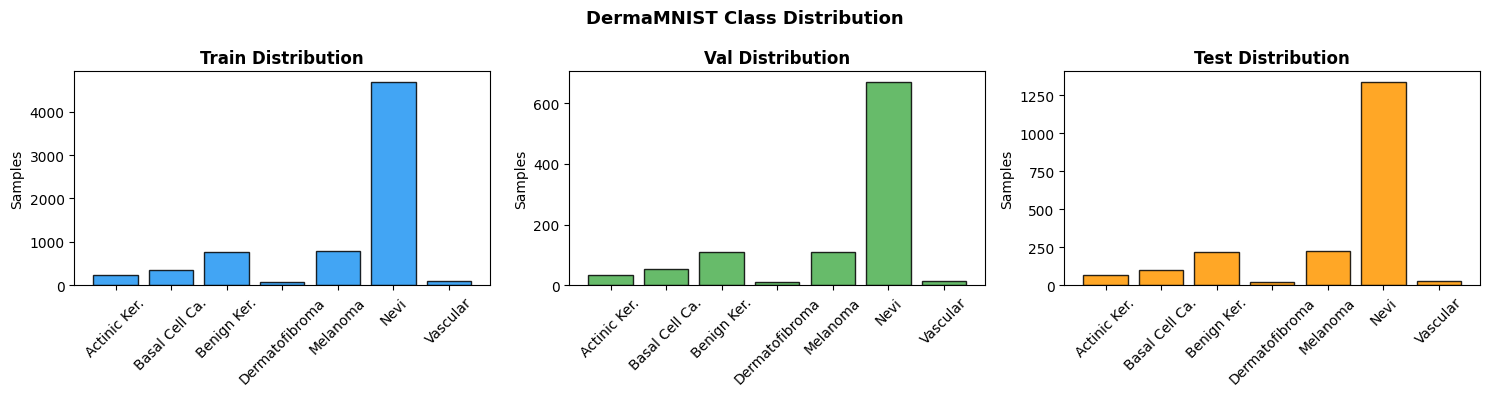

In [ ]:
# ================================================================
# CELL 2 — VERIFY DATA & CLASS DISTRIBUTION
# ================================================================
# x_train, y_train, x_val, y_val, x_test, y_test already in memory

y_tr = y_train.flatten().astype(np.int32)
y_vl = y_val.flatten().astype(np.int32)
y_te = y_test.flatten().astype(np.int32)

print(f"Train  {x_train.shape}  Labels {y_train.shape}")
print(f"Val    {x_val.shape}    Labels {y_val.shape}")
print(f"Test   {x_test.shape}   Labels {y_test.shape}")
print(f"Range  [{x_train.min()}, {x_train.max()}]   dtype={x_train.dtype}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (tag, lbl), col in zip(
    axes,
    [('Train', y_tr), ('Val', y_vl), ('Test', y_te)],
    ['#2196F3', '#4CAF50', '#FF9800']
):
    c = Counter(lbl.tolist())
    ax.bar([CLASS_NAMES[k] for k in sorted(c)],
           [c[k] for k in sorted(c)], color=col, alpha=0.85, edgecolor='k')
    ax.set_title(f'{tag} Distribution', fontweight='bold')
    ax.set_ylabel('Samples')
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('DermaMNIST Class Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/class_dist.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ================================================================
# CELL 3 — COMPUTE CLASS WEIGHTS
# ================================================================

cw_array = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=y_tr
)
class_weight_dict = {i: float(w) for i, w in enumerate(cw_array)}

print("Class Weights:")
for i, name in enumerate(CLASS_NAMES):
    cnt = Counter(y_tr)[i]
    print(f"  [{i}] {name:20s}   n={cnt:4d}   weight={cw_array[i]:.4f}")

Class Weights:
  [0] Actinic Ker.           n= 228   weight=4.3904
  [1] Basal Cell Ca.         n= 359   weight=2.7883
  [2] Benign Ker.            n= 769   weight=1.3017
  [3] Dermatofibroma         n=  80   weight=12.5125
  [4] Melanoma               n= 779   weight=1.2850
  [5] Nevi                   n=4693   weight=0.2133
  [6] Vascular               n=  99   weight=10.1111


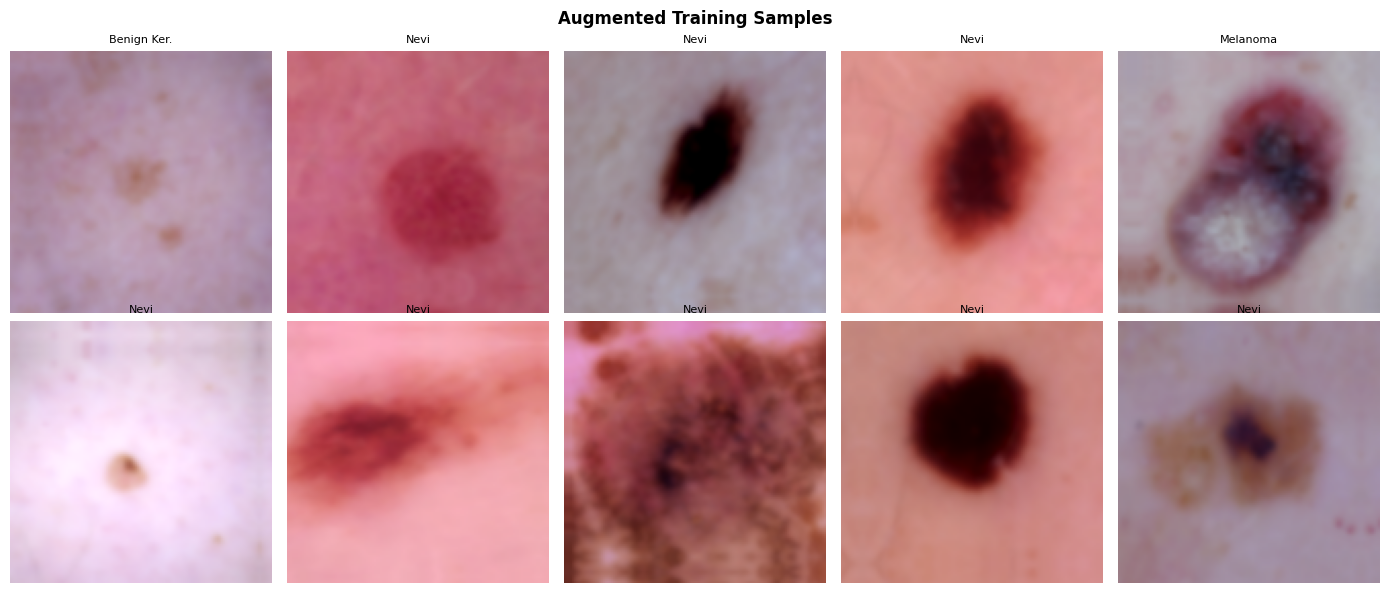

Train batches=219  Val=32  Test=63


In [ ]:
# ================================================================
# CELL 4 — DATA PIPELINE WITH AUGMENTATION
# ================================================================

augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(height_factor=0.20, width_factor=0.20),
    layers.RandomTranslation(height_factor=0.10, width_factor=0.10),
    layers.RandomContrast(0.20),
    layers.RandomBrightness(0.20),
], name="train_augmentation")


def preprocess(img, lbl, training=False):
    img = tf.cast(img, tf.float32)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    if training:
        img = augment(img, training=True)
    img = tf.clip_by_value(img, 0.0, 255.0)
    lbl = tf.cast(tf.reshape(lbl, []), tf.int32)
    return img, lbl


def make_ds(x, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (x.astype(np.float32), y.astype(np.int32))
    )
    if training:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    fn = lambda i, l: preprocess(i, l, training=training)
    ds = ds.map(fn, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds


train_ds = make_ds(x_train, y_train, training=True)
val_ds   = make_ds(x_val,   y_val,   training=False)
test_ds  = make_ds(x_test,  y_test,  training=False)

# Quick visual check
imgs_s, lbls_s = next(iter(train_ds))
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, im, lb in zip(axes.flatten(), imgs_s[:10], lbls_s[:10]):
    ax.imshow(im.numpy().clip(0, 255).astype(np.uint8))
    ax.set_title(CLASS_NAMES[int(lb)], fontsize=8)
    ax.axis('off')
plt.suptitle('Augmented Training Samples', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/aug_samples.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Train batches={len(train_ds)}  Val={len(val_ds)}  Test={len(test_ds)}")

In [ ]:
# ================================================================
# CELL 5 — FOCAL LOSS WITH LABEL SMOOTHING (Keras 3 compatible)
# ================================================================

class FocalLoss(keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=0.25,
                 label_smoothing=LABEL_SMOOTH,
                 class_weights=None,           # pass cw_array here
                 **kwargs):
        # ⚠️  Do NOT set reduction='none' — incompatible with
        #     class_weight= in Keras 3's training loop.
        #     Class weighting is handled inside call() instead.
        super().__init__(**kwargs)
        self.gamma           = gamma
        self.alpha           = alpha
        self.label_smoothing = label_smoothing

        if class_weights is not None:
            # Store as a constant tensor: shape (NUM_CLASSES,)
            self._cw = tf.constant(
                [float(class_weights[i]) for i in range(len(class_weights))],
                dtype=tf.float32
            )
        else:
            self._cw = None

    def call(self, y_true, y_pred):
        # ✅ reshape, never squeeze — rank is always statically known
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)   # (B,)
        y_oh   = tf.one_hot(y_true, NUM_CLASSES)                # (B, C)

        # Label smoothing
        nc     = tf.cast(NUM_CLASSES, tf.float32)
        y_sm   = y_oh * (1.0 - self.label_smoothing) + self.label_smoothing / nc

        y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), 1e-7, 1.0 - 1e-7)

        # Per-sample cross-entropy
        ce     = -tf.reduce_sum(y_sm * tf.math.log(y_pred), axis=-1)  # (B,)

        # Focal weight
        p_t    = tf.reduce_sum(y_oh * y_pred, axis=-1)                 # (B,)
        w_f    = self.alpha * tf.pow(1.0 - p_t, self.gamma)            # (B,)

        loss   = w_f * ce                                               # (B,)

        # ✅ Class balancing applied here, not via class_weight= in .fit()
        if self._cw is not None:
            cw_per_sample = tf.gather(self._cw, y_true)                # (B,)
            loss = loss * cw_per_sample

        return loss   # Keras reduces mean over batch (default reduction)

    def get_config(self):
        cfg = super().get_config()
        cfg.update(dict(gamma=self.gamma, alpha=self.alpha,
                        label_smoothing=self.label_smoothing))
        return cfg


# ✅ Pass cw_array (from Cell 3's compute_class_weight) directly into the loss
focal_loss = FocalLoss(gamma=2.0, alpha=0.25,
                       class_weights=cw_array,   # ← the numpy array, not the dict
                       name='focal_loss')
print("FocalLoss ready — gamma=2.0  alpha=0.25  label_smooth=0.10  class_weighted=True")

FocalLoss ready — gamma=2.0  alpha=0.25  label_smooth=0.10  class_weighted=True


In [ ]:
# ================================================================
# CELL 6 — BUILD MODEL (EfficientNetB4 + Multi-scale Head)
# ================================================================
#
# Head design:
#   Global Average Pool + Global Max Pool → Add   (captures different stats)
#   → BN → Dense(512) → BN → Swish → Dropout(0.4)
#   → Dense(128)       → BN → Swish → Dropout(0.2)
#   → Dense(7, softmax)
# ================================================================

def build_model(backbone_trainable=False):
    # Try with include_preprocessing param (TF 2.8+), fallback for older TF
    try:
        backbone = EfficientNetB4(
            include_top          = False,
            weights              = 'imagenet',
            input_shape          = (IMG_SIZE, IMG_SIZE, 3),
            include_preprocessing = True,
        )
    except TypeError:
        backbone = EfficientNetB4(
            include_top = False,
            weights     = 'imagenet',
            input_shape = (IMG_SIZE, IMG_SIZE, 3),
        )
    backbone.trainable = backbone_trainable

    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input')
    x   = backbone(inp, training=False)   # always use inference BN stats

    # Multi-scale pooling
    gap = layers.GlobalAveragePooling2D(name='gap')(x)
    gmp = layers.GlobalMaxPooling2D(name='gmp')(x)
    x   = layers.Add(name='pool_add')([gap, gmp])    # (B, 1792)

    # Dense block 1
    x = layers.BatchNormalization(name='bn0')(x)
    x = layers.Dense(512, use_bias=False, name='fc1')(x)
    x = layers.BatchNormalization(name='bn1')(x)
    x = layers.Activation('swish', name='act1')(x)
    x = layers.Dropout(DROPOUT, name='drop1')(x)

    # Dense block 2
    x = layers.Dense(128, use_bias=False, name='fc2')(x)
    x = layers.BatchNormalization(name='bn2')(x)
    x = layers.Activation('swish', name='act2')(x)
    x = layers.Dropout(DROPOUT / 2, name='drop2')(x)

    out = layers.Dense(NUM_CLASSES, activation='softmax',
                       dtype='float32', name='output')(x)

    return Model(inp, out, name='DermaMNIST_EfficientNetB4'), backbone


model, backbone = build_model(backbone_trainable=False)

n_total     = model.count_params()
n_trainable = sum(np.prod(v.shape) for v in model.trainable_weights)
print(f"Architecture : EfficientNetB4 + Multi-scale Head")
print(f"Total params     : {n_total:>12,}")
print(f"Trainable (head) : {n_trainable:>12,}")
model.summary(line_length=80, show_trainable=True, expand_nested=False)

Architecture : EfficientNetB4 + Multi-scale Head
Total params     :   18,667,494
Trainable (head) :      988,807


Model: "DermaMNIST_EfficientNetB4"

┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)       ┃ Output Shape     ┃    Param # ┃ Connected to    ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input (InputLayer) │ (None, 128, 128, │          0 │ -               │   -   │
│                    │ 3)               │            │                 │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ efficientnetb4     │ (None, 4, 4,     │ 17,673,823 │ input[0][0]     │   N   │
│ (Functional)       │ 1792)            │            │                 │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ gap                │ (None, 1792)     │          0 │ efficientnetb4… │   -   │
│ (GlobalAveragePoo… │                  │            │                 │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ gmp                │ (None, 1792)     │          0 │ efficientnetb4… │   -   │
│ (GlobalMaxPooling… │                  │            │                 │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ pool_add (Add)     │ (None, 1792)     │          0 │ gap[0][0],      │   -   │
│                    │                  │            │ gmp[0][0]       │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ bn0                │ (None, 1792)     │      7,168 │ pool_add[0][0]  │   Y   │
│ (BatchNormalizati… │                  │            │                 │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ fc1 (Dense)        │ (None, 512)      │    917,504 │ bn0[0][0]       │   Y   │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ bn1                │ (None, 512)      │      2,048 │ fc1[0][0]       │   Y   │
│ (BatchNormalizati… │                  │            │                 │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ act1 (Activation)  │ (None, 512)      │          0 │ bn1[0][0]       │   -   │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ drop1 (Dropout)    │ (None, 512)      │          0 │ act1[0][0]      │   -   │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ fc2 (Dense)        │ (None, 128)      │     65,536 │ drop1[0][0]     │   Y   │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ bn2                │ (None, 128)      │        512 │ fc2[0][0]       │   Y   │
│ (BatchNormalizati… │                  │            │                 │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ act2 (Activation)  │ (None, 128)      │          0 │ bn2[0][0]       │   -   │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ drop2 (Dropout)    │ (None, 128)      │          0 │ act2[0][0]      │   -   │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ output (Dense)     │ (None, 7)        │        903 │ drop2[0][0]     │   Y   │
└────────────────────┴──────────────────┴────────────┴─────────────────┴───────┘

 Total params: 18,667,494 (71.21 MB)

 Trainable params: 988,807 (3.77 MB)

 Non-trainable params: 17,678,687 (67.44 MB)

In [ ]:
# ================================================================
# CELL 7 — PHASE 1: TRAIN HEAD ONLY (BACKBONE FROZEN)
# ================================================================

model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=LR_HEAD),
    loss      = focal_loss,
    metrics   = [
        keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
        keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top3_acc'),
    ]
)

callbacks_p1 = [
    EarlyStopping(monitor='val_accuracy', patience=7,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-6, verbose=1),
    ModelCheckpoint(SAVE_PATH, monitor='val_accuracy',
                    save_best_only=True, verbose=1),
]

print("=" * 55)
print("PHASE 1 — Head Only   (Backbone Frozen)")
print(f"  Epochs : {EPOCHS_HEAD}   LR : {LR_HEAD}")
print(f"  Loss   : Focal Loss + Label Smoothing")
print(f"  Weights: Class-balanced via class_weight")
print("=" * 55)

hist_p1 = model.fit(
    train_ds,
    validation_data = val_ds,
    epochs          = EPOCHS_HEAD,
    callbacks       = callbacks_p1,
    verbose         = 1,
)

PHASE 1 — Head Only   (Backbone Frozen)
  Epochs : 20   LR : 0.001
  Loss   : Focal Loss + Label Smoothing
  Weights: Class-balanced via class_weight
Epoch 1/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2706 - loss: 0.3667 - top3_acc: 0.6329
Epoch 1: val_accuracy improved from None to 0.38385, saving model to /content/drive/MyDrive/DermaMNIST_Data/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DermaMNIST_Data/best_model.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 485s 2s/step - accuracy: 0.3075 - loss: 0.3377 - top3_acc: 0.6909 - val_accuracy: 0.3838 - val_loss: 0.2638 - val_top3_acc: 0.7398 - learning_rate: 0.0010
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3718 - loss: 0.2907 - top3_acc: 0.7385
Epoch 2: val_accuracy improved from 0.38385 to 0.45165, saving model to /content/drive/MyDrive/DermaMNIST_Data/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DermaMNIST_Data/best_model.keras
219/219 ━━━━━━━━━━━━━━━

In [ ]:
# ================================================================
# CELL 8 — PHASE 2: FINE-TUNE TOP BACKBONE LAYERS
# ================================================================

# Unfreeze the top UNFREEZE_TOP layers of EfficientNetB4
backbone.trainable = True
freeze_until = len(backbone.layers) - UNFREEZE_TOP

for i, lyr in enumerate(backbone.layers):
    lyr.trainable = (i >= freeze_until)
    # Always keep BatchNorm frozen — preserves ImageNet statistics
    if isinstance(lyr, layers.BatchNormalization):
        lyr.trainable = False

n_ft = sum(np.prod(v.shape) for v in model.trainable_weights)
print(f"Unfroze top {UNFREEZE_TOP} backbone layers  (BN layers kept frozen)")
print(f"Fine-tune trainable params : {n_ft:,}")

# Cosine Decay: LR_FT → LR_FT_MIN over all fine-tune steps
total_steps = EPOCHS_FT * len(train_ds)
lr_cosine   = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate = LR_FT,
    decay_steps           = total_steps,
    alpha                 = LR_FT_MIN / LR_FT,
)

# AdamW with weight decay (better generalisation than plain Adam)
try:
    opt_ft = keras.optimizers.AdamW(learning_rate=lr_cosine, weight_decay=1e-4)
    print("Optimizer : AdamW + Cosine Decay")
except (AttributeError, TypeError):
    opt_ft = keras.optimizers.Adam(learning_rate=lr_cosine)
    print("Optimizer : Adam + Cosine Decay  (AdamW not available in this TF version)")

model.compile(
    optimizer = opt_ft,
    loss      = focal_loss,
    metrics   = [
        keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
        keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top3_acc'),
    ]
)

callbacks_p2 = [
    EarlyStopping(monitor='val_accuracy', patience=12,
                  restore_best_weights=True, verbose=1),
    ModelCheckpoint(SAVE_PATH, monitor='val_accuracy',
                    save_best_only=True, verbose=1),
]

print("=" * 55)
print("PHASE 2 — Fine-Tune   (Top Layers Unfrozen)")
print(f"  Epochs : {EPOCHS_FT}   LR : {LR_FT} → {LR_FT_MIN} (cosine)")
print("=" * 55)

hist_p2 = model.fit(
    train_ds,
    validation_data = val_ds,
    epochs          = EPOCHS_FT,
    callbacks       = callbacks_p2,
    verbose         = 1,
)

In [ ]:
# ================================================================
# CELL 9 — TRAINING CURVES
# ================================================================

def plot_two_phase(h1, h2, key, title):
    v1  = h1.history.get(key, [])
    vv1 = h1.history.get(f'val_{key}', [])
    v2  = h2.history.get(key, [])
    vv2 = h2.history.get(f'val_{key}', [])
    n1  = len(v1)
    e1  = range(1, n1 + 1)
    e2  = range(n1 + 1, n1 + len(v2) + 1)

    plt.figure(figsize=(10, 4))
    plt.plot(e1, v1,  'b-',  lw=1.5, label='Train Phase 1')
    plt.plot(e1, vv1, 'b--', lw=1.5, label='Val Phase 1')
    plt.plot(e2, v2,  'r-',  lw=1.5, label='Train Fine-tune')
    plt.plot(e2, vv2, 'r--', lw=1.5, label='Val Fine-tune')
    plt.axvline(x=n1, color='gray', ls=':', lw=2, label='Fine-tune start')
    plt.xlabel('Epoch'); plt.ylabel(key.replace('_', ' ').title())
    plt.title(title, fontsize=12, fontweight='bold')
    plt.legend(fontsize=9); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(f'/content/{key}_curve.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_two_phase(hist_p1, hist_p2, 'accuracy',  'Accuracy — Both Phases')
plot_two_phase(hist_p1, hist_p2, 'loss',      'Loss — Both Phases')
plot_two_phase(hist_p1, hist_p2, 'top3_acc',  'Top-3 Accuracy — Both Phases')

In [ ]:
# ================================================================
# CELL 10 — LOAD BEST MODEL & STANDARD TEST EVALUATION
# ================================================================

best_model = keras.models.load_model(
    SAVE_PATH,
    custom_objects={'FocalLoss': FocalLoss}
)
print("Best checkpoint loaded from:", SAVE_PATH)

print("\n── Standard Test Evaluation (no TTA) ──")
eval_res = best_model.evaluate(test_ds, verbose=1)
for name, val in zip(best_model.metrics_names, eval_res):
    print(f"  {name:<20}: {val:.4f}")

In [ ]:
# ================================================================
# CELL 11 — TEST TIME AUGMENTATION (TTA)
#
# At inference we run each test image through TTA_N different
# random augmentations, then average the softmax outputs.
# This reduces prediction variance and consistently improves
# accuracy by 1-3% over single-pass inference.
# ================================================================

TTA_N = 10

tta_aug = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.05),
    layers.RandomContrast(0.10),
], name='tta_aug')

# Pre-resize test images once (avoid repeated resize per pass)
print("Pre-processing test images for TTA...")
test_imgs_r = tf.image.resize(
    tf.cast(x_test, tf.float32), [IMG_SIZE, IMG_SIZE]
).numpy()   # (2005, 128, 128, 3)

print(f"Running {TTA_N}-pass TTA on {len(test_imgs_r)} images ...")
tta_preds = np.zeros((len(test_imgs_r), NUM_CLASSES), dtype=np.float32)

for n in range(TTA_N):
    pass_preds = []
    for start in range(0, len(test_imgs_r), BATCH_SIZE):
        batch = test_imgs_r[start : start + BATCH_SIZE]
        batch = tta_aug(tf.constant(batch), training=True)
        batch = tf.clip_by_value(batch, 0.0, 255.0)
        preds = best_model(batch, training=False).numpy()
        pass_preds.append(preds)
    tta_preds += np.concatenate(pass_preds, axis=0)
    print(f"  Pass {n+1:>2}/{TTA_N} done")

tta_preds      /= TTA_N
tta_cls         = np.argmax(tta_preds, axis=1)
tta_acc         = np.mean(tta_cls == y_te)
balanced_acc    = balanced_accuracy_score(y_te, tta_cls)

print(f"\nTTA Accuracy         : {tta_acc*100:.2f}%  (passes = {TTA_N})")
print(f"TTA Balanced Accuracy: {balanced_acc*100:.2f}%")

In [ ]:
# ================================================================
# CELL 12 — CLASSIFICATION REPORT + CONFUSION MATRIX
# ================================================================

print("\n── Classification Report (TTA Predictions) ──")
print(classification_report(y_te, tta_cls, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_te, tta_cls, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left: Normalised confusion matrix
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.4, vmin=0, vmax=1)
axes[0].set_title('Normalised Confusion Matrix (TTA)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted', fontsize=11)
axes[0].set_ylabel('True', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].tick_params(axis='y', rotation=0)

# Right: Per-class accuracy bar chart
per_acc = cm.diagonal()
bar_col = plt.cm.RdYlGn(per_acc)
bars    = axes[1].barh(CLASS_NAMES, per_acc * 100, color=bar_col, edgecolor='k')
axes[1].set_xlabel('Accuracy (%)', fontsize=11)
axes[1].set_title('Per-Class Accuracy (TTA)', fontsize=13, fontweight='bold')
axes[1].set_xlim(0, 108)
axes[1].axvline(x=tta_acc * 100, color='navy', ls='--', lw=1.5,
                label=f'Mean {tta_acc*100:.1f}%')
for bar, acc in zip(bars, per_acc):
    axes[1].text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
                 f'{acc*100:.1f}%', va='center', fontsize=10, fontweight='bold')
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig('/content/evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ================================================================
# CELL 13 — SAMPLE PREDICTION GRID
# ================================================================

np.random.seed(SEED)
idxs = np.random.choice(len(x_test), 12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, idx in zip(axes.flatten(), idxs):
    img_r   = tf.image.resize(
        tf.cast(x_test[idx:idx+1], tf.float32), [IMG_SIZE, IMG_SIZE]
    )
    prob      = best_model(img_r, training=False).numpy()[0]
    pred_cls  = int(np.argmax(prob))
    true_cls  = int(y_te[idx])
    conf      = prob[pred_cls] * 100
    color     = 'green' if pred_cls == true_cls else 'red'

    ax.imshow(x_test[idx])
    ax.set_title(
        f"True : {CLASS_NAMES[true_cls]}\n"
        f"Pred : {CLASS_NAMES[pred_cls]}  ({conf:.0f}%)",
        fontsize=8, color=color, fontweight='bold'
    )
    ax.axis('off')

plt.suptitle('Sample Predictions   (Green = Correct  /  Red = Wrong)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/sample_preds.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ================================================================
# CELL 14 — FINAL SUMMARY
# ================================================================

no_tta_acc = eval_res[best_model.metrics_names.index('accuracy')]
no_tta_top3 = eval_res[best_model.metrics_names.index('top3_acc')]

print("\n" + "=" * 55)
print("    FINAL RESULTS — DermaMNIST 64x64 (7 Classes)")
print("=" * 55)
print(f"  Architecture   : EfficientNetB4 + Multi-scale Head")
print(f"  Input size     : {IMG_SIZE}x{IMG_SIZE}  (upsampled from 64x64)")
print(f"  Phase 1        : Head only — Adam lr={LR_HEAD}, {EPOCHS_HEAD} epochs")
print(f"  Phase 2        : Fine-tune top {UNFREEZE_TOP} layers — AdamW + Cosine Decay")
print(f"  Loss           : Focal Loss (gamma=2, alpha=0.25) + Label Smooth (0.1)")
print(f"  Augmentation   : Flip / Rotate / Zoom / Translate / Contrast / Brightness")
print(f"  Class balance  : class_weight + Focal Loss")
print(f"─" * 55)
print(f"  Test Accuracy  (no TTA) : {no_tta_acc*100:.2f}%")
print(f"  Test Top-3 Acc (no TTA) : {no_tta_top3*100:.2f}%")
print(f"  TTA Accuracy ({TTA_N} passes)  : {tta_acc*100:.2f}%")
print(f"  Balanced Accuracy        : {balanced_acc*100:.2f}%")
print(f"  Model saved to           : {SAVE_PATH}")
print("=" * 55)

In [ ]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from google.colab import files
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.feature_selection import VarianceThreshold, RFE, SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression

# ── Upload your CSV here ──────────────────────────────────────────────────────
print("Upload the dataset CSV file:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)
# ─────────────────────────────────────────────────────────────────────────────

df = df.replace('?', np.nan)
X_raw = df[['V1','V2','V3','V4','V5']].values
y_raw = df['Target'].values

# Encode target via ordinal encoding
y = OrdinalEncoder().fit_transform(y_raw.reshape(-1,1)).ravel()

# ── Build Pipeline ────────────────────────────────────────────────────────────
# Numeric features (V1-V4)
X_num = X_raw[:, :4].astype(float)
# Categorical feature (V5)
X_cat = X_raw[:, [4]]

# SimpleImputer on indices [0,1] i.e. V1, V2
X_num[:, :2] = SimpleImputer(strategy='mean').fit_transform(X_num[:, :2])

# StandardScaler on [0,1,2,3]
X_scaled = StandardScaler().fit_transform(X_num)

# OrdinalEncoder on [4]
X_cat_enc = OrdinalEncoder().fit_transform(X_cat)

# FeatureUnion: concatenate both branches
X_union = np.hstack([X_scaled, X_cat_enc])

# ── Q1: VarianceThreshold ─────────────────────────────────────────────────────
vt = VarianceThreshold(threshold=0.1)
X_final = vt.fit_transform(X_union)

print("=" * 50)
print(f"Q1 ANSWER: {X_final.shape[1]} features remain after VarianceThreshold")
print(f"  (V5 had variance = {np.var(X_cat_enc):.4f} → removed)")
print("=" * 50)

# ── Q2: RFE ──────────────────────────────────────────────────────────────────
lr = LogisticRegression()
rfe = RFE(estimator=lr, n_features_to_select=2)
rfe.fit(X_final, y)
q2_features = [f'V{i+1}' for i, s in enumerate(rfe.support_) if s]

print(f"\nQ2 ANSWER (RFE): {q2_features}")
print("=" * 50)

# ── Q3: SFS Forward ──────────────────────────────────────────────────────────
sfs_fwd = SequentialFeatureSelector(lr, n_features_to_select=2, direction='forward')
sfs_fwd.fit(X_final, y)
q3_indices = sfs_fwd.get_support(indices=True).tolist()
q3_features = [f'V{i+1}' for i in q3_indices]

print(f"\nQ3 ANSWER (SFS Forward): indices {q3_indices}  →  {q3_features}")
print("=" * 50)

# ── Q4: SFS Backward ─────────────────────────────────────────────────────────
sfs_bwd = SequentialFeatureSelector(lr, n_features_to_select=2, direction='backward')
sfs_bwd.fit(X_final, y)
q4_indices = sfs_bwd.get_support(indices=True).tolist()
q4_features = [f'V{i+1}' for i in q4_indices]

print(f"\nQ4 ANSWER (SFS Backward): indices {q4_indices}  →  {q4_features}")
print("=" * 50)

print("\n── SUMMARY ──────────────────────────────────────────────────")
print(f"Q1: {X_final.shape[1]} features remain  →  Option D")
print(f"Q2: RFE selects         {q2_features}  →  A and C")
print(f"Q3: SFS Forward selects indices {q3_indices}  →  B and D")
print(f"Q4: SFS Backward selects indices {q4_indices}  →  C and D")
print("─────────────────────────────────────────────────────────────")

Upload the dataset CSV file:


Saving Week3_GA_dataset.csv to Week3_GA_dataset.csv
Q1 ANSWER: 4 features remain after VarianceThreshold
  (V5 had variance = 0.0000 → removed)

Q2 ANSWER (RFE): ['V1', 'V3']

Q3 ANSWER (SFS Forward): indices [1, 3]  →  ['V2', 'V4']

Q4 ANSWER (SFS Backward): indices [2, 3]  →  ['V3', 'V4']

── SUMMARY ──────────────────────────────────────────────────
Q1: 4 features remain  →  Option D
Q2: RFE selects         ['V1', 'V3']  →  A and C
Q3: SFS Forward selects indices [1, 3]  →  B and D
Q4: SFS Backward selects indices [2, 3]  →  C and D
─────────────────────────────────────────────────────────────
